In [60]:

from pathlib import Path
import pandas as pd

DATA_DIR = Path("raw\\dataset0304")

issues = pd.read_csv(DATA_DIR / "issues.csv")
history = pd.read_csv(DATA_DIR / "issue_status_history.csv")
projects = pd.read_csv(DATA_DIR / "projects.csv")
teams = pd.read_csv(DATA_DIR / "teams.csv")
sprints = pd.read_csv(DATA_DIR / "sprints.csv")
releases = pd.read_csv(DATA_DIR / "releases.csv")
release_issues = pd.read_csv(DATA_DIR / "release_issues.csv")

# Отбираем атрибуты, необходимые для анализа
issues = issues[
    [
        "issue_id",
        "project_id",
        "team_id",
        "created_at",
        "resolved_at",
        "current_status"
    ]
].copy()

history = history[
    ["issue_id", "status", "changed_at"]
].copy()

# Преобразуем даты
issues["created_at"] = pd.to_datetime(issues["created_at"])
issues["resolved_at"] = pd.to_datetime(issues["resolved_at"])
history["changed_at"] = pd.to_datetime(history["changed_at"])
releases["release_date"] = pd.to_datetime(releases["release_date"])

# Добавляем названия проектов
issues = issues.merge(
    projects[["project_id", "project_name"]],
    on="project_id",
    how="left",
    validate="many_to_one"
)

print("Количество задач:", len(issues))
print("Завершённых:", issues["resolved_at"].notna().sum())
print("Незавершённых:", issues["resolved_at"].isna().sum())

display(issues.sample(5))


Количество задач: 500
Завершённых: 415
Незавершённых: 85


,issue_id,project_id,team_id,created_at,resolved_at,current_status,project_name
279,280,2,1,2025-03-08 10:50:00,NaT,Selected for Development,Project B
77,78,1,2,2024-10-07 15:16:00,2024-10-22 19:16:00,Done,Project A
439,440,2,3,2024-12-21 16:42:00,2024-12-26 19:42:00,Done,Project B
436,437,2,3,2024-04-22 13:37:00,2024-04-25 14:37:00,Done,Project B
325,326,2,2,2024-06-08 09:42:00,2024-07-17 11:42:00,Done,Project B


In [61]:
print("Пропуски в таблице задач:")
print(issues.isnull().sum())

print("\nПропуски в истории статусов:")
print(history.isnull().sum())

print("\nДубликаты:")
print("issues:", issues.duplicated().sum())
print("history:", history.duplicated().sum())

Пропуски в таблице задач:
issue_id           0
project_id         0
team_id            0
created_at         0
resolved_at       85
current_status     0
project_name       0
dtype: int64

Пропуски в истории статусов:
issue_id      0
status        0
changed_at    0
dtype: int64

Дубликаты:
issues: 0
history: 104


In [62]:

# Преобразуем даты в datetime
for col in ["created_at", "resolved_at"]:
    issues[col] = pd.to_datetime(
        issues[col], errors="coerce"
    )

history["changed_at"] = pd.to_datetime(
    history["changed_at"], errors="coerce"
)

# Удаляем полные дубликаты событий
history_clean = history.drop_duplicates().copy()

# Проверяем хронологию событий
history_clean = history_clean.merge(
    issues[["issue_id", "created_at"]],
    on="issue_id",
    how="left",
    validate="many_to_one"
)


history_clean

,issue_id,status,changed_at,created_at
0,1,Backlog,2025-08-02 11:23:00,2025-08-02 11:23:00
1,1,Selected for Development,2025-08-06 13:23:00,2025-08-02 11:23:00
2,1,In Progress,2025-08-10 16:23:00,2025-08-02 11:23:00
3,1,Code Review,2025-08-16 20:23:00,2025-08-02 11:23:00
4,1,QA,2025-08-19 00:23:00,2025-08-02 11:23:00
...,...,...,...,...
3043,499,Code Review,2025-11-08 20:48:00,2025-10-23 17:48:00
3044,499,QA,2025-11-16 22:48:00,2025-10-23 17:48:00
3045,499,Done,2025-11-19 20:48:00,2025-10-23 17:48:00
3046,500,Backlog,2025-08-20 11:18:00,2025-08-20 11:18:00


In [63]:
invalid = (
    history_clean["changed_at"]
    < history_clean["created_at"]
)

print("Некорректных переходов:", invalid.sum())

# Исключаем невозможные по времени события
history_clean = history_clean.loc[
    ~invalid,
    ["issue_id", "status", "changed_at"]
].copy()

history_clean = history_clean.sort_values(
    ["issue_id", "changed_at"]
).reset_index(drop=True)

print("Событий после очистки:", len(history_clean))

Некорректных переходов: 11
Событий после очистки: 3037


In [64]:
history_clean[invalid]

C:\Users\Admin\AppData\Local\Temp\ipykernel_16768\3899955971.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  history_clean[invalid]


,issue_id,status,changed_at
119,21,Backlog,2025-01-13 13:38:00
292,49,In Progress,2025-08-04 22:30:00
344,59,Code Review,2025-02-21 23:53:00
553,90,Done,2024-02-18 09:25:00
879,145,QA,2025-05-25 15:04:00
1163,191,Done,2025-04-28 18:11:00
1792,300,Backlog,2025-09-24 09:08:00
2137,357,Code Review,2024-06-20 09:37:00
2144,358,In Progress,2024-06-08 21:52:00
2335,386,Code Review,2026-01-12 01:59:00


In [65]:

# Последняя дата завершения каждой задачи
final_done = (
    history_clean[
        history_clean["status"] == "Done"
    ]
    .groupby("issue_id")["changed_at"]
    .max()
)

issues["final_done_at"] = (
    issues["issue_id"].map(final_done)
)

# Проверяем согласованность с текущим статусом
inconsistent = (
    (issues["current_status"] == "Done")
    & issues["final_done_at"].isna()
)

print("Завершённых задач без даты:",
      inconsistent.sum())

# Контроль количества записей
print("Всего задач:", len(issues))
print("Завершённых:",
      (issues["current_status"] == "Done").sum())


Завершённых задач без даты: 0
Всего задач: 500
Завершённых: 415


In [66]:
issues[issues["resolved_at"] != issues["final_done_at"]]

,issue_id,project_id,team_id,created_at,resolved_at,current_status,project_name,final_done_at
5,6,1,1,2024-11-28 17:40:00,2024-12-15 18:40:00,Done,Project A,2024-12-24 18:40:00
6,7,1,1,2024-11-11 10:28:00,NaT,Backlog,Project A,NaT
9,10,1,1,2024-06-09 16:36:00,NaT,In Progress,Project A,NaT
16,17,1,1,2024-07-14 12:40:00,2024-08-08 12:40:00,Done,Project A,2024-08-15 12:40:00
18,19,1,1,2025-09-22 16:53:00,NaT,Backlog,Project A,NaT
...,...,...,...,...,...,...,...,...
484,485,2,4,2025-01-30 09:18:00,NaT,Selected for Development,Project B,NaT
492,493,2,4,2025-08-14 15:31:00,2025-09-03 19:31:00,Done,Project B,2025-09-11 19:31:00
496,497,2,4,2025-02-15 15:03:00,2025-03-16 17:03:00,Done,Project B,2025-03-23 17:03:00
497,498,2,4,2025-08-28 08:34:00,NaT,Selected for Development,Project B,NaT


In [67]:

# Первое начало выполнения каждой задачи
start_times = (
    history_clean[
        history_clean["status"] == "In Progress"
    ]
    .groupby("issue_id")["changed_at"]
    .min()
)

# Последний переход каждой задачи в Done
finish_times = (
    history_clean[
        history_clean["status"] == "Done"
    ]
    .groupby("issue_id")["changed_at"]
    .max()
)

# Создаём рабочую таблицу
df = issues.copy()

df["started_at"] = df["issue_id"].map(start_times)
df["completed_at"] = df["issue_id"].map(finish_times)

# Не считаем завершёнными задачи,
# текущий статус которых отличается от Done
df.loc[
    df["current_status"] != "Done",
    "completed_at"
] = pd.NaT

df["is_completed"] = df["completed_at"].notna()

# Продолжительность в календарных днях
df["lead_time_days"] = (
    (df["completed_at"] - df["created_at"])
    .dt.total_seconds() / 86400
)

df["cycle_time_days"] = (
    (df["completed_at"] - df["started_at"])
    .dt.total_seconds() / 86400
)

df["waiting_days"] = (
    (df["started_at"] - df["created_at"])
    .dt.total_seconds() / 86400
)

display(df.head())


,issue_id,project_id,team_id,created_at,resolved_at,current_status,project_name,final_done_at,started_at,completed_at,is_completed,lead_time_days,cycle_time_days,waiting_days
0,1,1,1,2025-08-02 11:23:00,2025-08-19 13:23:00,Done,Project A,2025-08-19 13:23:00,2025-08-10 16:23:00,2025-08-19 13:23:00,True,17.083333,8.875000,8.208333
1,2,1,1,2024-10-17 16:09:00,2024-11-04 17:09:00,Done,Project A,2024-11-04 17:09:00,2024-10-27 00:09:00,2024-11-04 17:09:00,True,18.041667,8.708333,9.333333
2,3,1,1,2024-08-12 13:36:00,2024-08-17 17:36:00,Done,Project A,2024-08-17 17:36:00,2024-08-14 18:36:00,2024-08-17 17:36:00,True,5.166667,2.958333,2.208333
3,4,1,1,2025-01-28 11:46:00,2025-02-06 15:46:00,Done,Project A,2025-02-06 15:46:00,2025-01-30 18:46:00,2025-02-06 15:46:00,True,9.166667,6.875000,2.291667
4,5,1,1,2025-12-11 13:44:00,2026-01-09 14:44:00,Done,Project A,2026-01-09 14:44:00,2025-12-24 18:44:00,2026-01-09 14:44:00,True,29.041667,15.833333,13.208333


In [68]:

print("Всего задач:", len(df))
print("Завершённых:", df["is_completed"].sum())
print("Незавершённых:", (~df["is_completed"]).sum())

print("\nСтатистика временных показателей:")
display(
    df[["lead_time_days", "cycle_time_days", "waiting_days"]]
    .describe()
    .round(2)
)

# Проверяем отсутствие отрицательных длительностей
assert (df["lead_time_days"].dropna() >= 0).all()
assert (df["cycle_time_days"].dropna() >= 0).all()
assert (df["waiting_days"].dropna() >= 0).all()


Всего задач: 500
Завершённых: 415
Незавершённых: 85

Статистика временных показателей:


,lead_time_days,cycle_time_days,waiting_days
count,415.00,415.00,440.00
mean,17.64,9.59,7.87
std,10.36,7.04,6.10
min,1.04,0.04,0.04
25%,10.02,4.10,3.32
50%,16.08,7.79,6.25
75%,24.02,12.81,11.03
max,62.12,39.83,51.25


In [69]:

# Создаём полный диапазон календарных дней
dates = pd.date_range(
    df["created_at"].min().normalize(),
    history_clean["changed_at"].max().normalize(),
    freq="D"
)

# Считаем завершённые задачи по дням
throughput = (
    df[df["is_completed"]]
    .assign(date=lambda x: x["completed_at"].dt.normalize())
    .groupby(["project_id", "date"])
    .size()
    .rename("throughput")
)

# Добавляем дни с нулевым Throughput
index = pd.MultiIndex.from_product(
    [sorted(df["project_id"].unique()), dates],
    names=["project_id", "date"]
)

daily_throughput = (
    throughput.reindex(index, fill_value=0)
    .reset_index()
)

display(daily_throughput)


,project_id,date,throughput
0,1,2024-01-02,0
1,1,2024-01-03,0
2,1,2024-01-04,0
3,1,2024-01-05,0
4,1,2024-01-06,0
...,...,...,...
1519,2,2026-01-28,0
1520,2,2026-01-29,0
1521,2,2026-01-30,0
1522,2,2026-01-31,0


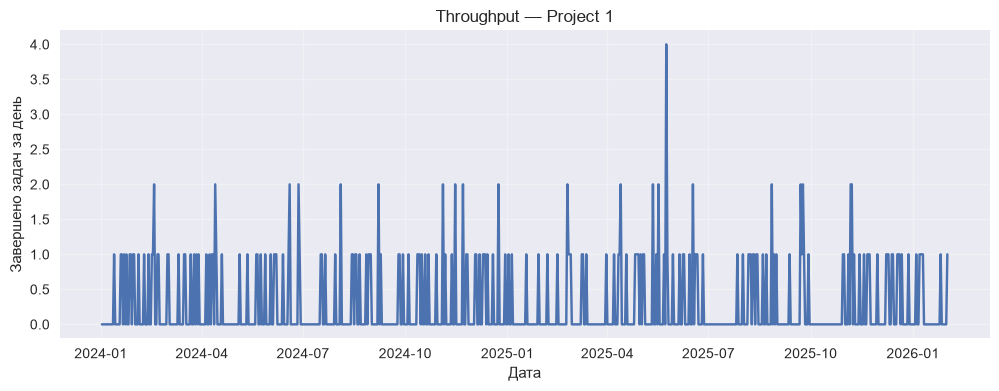

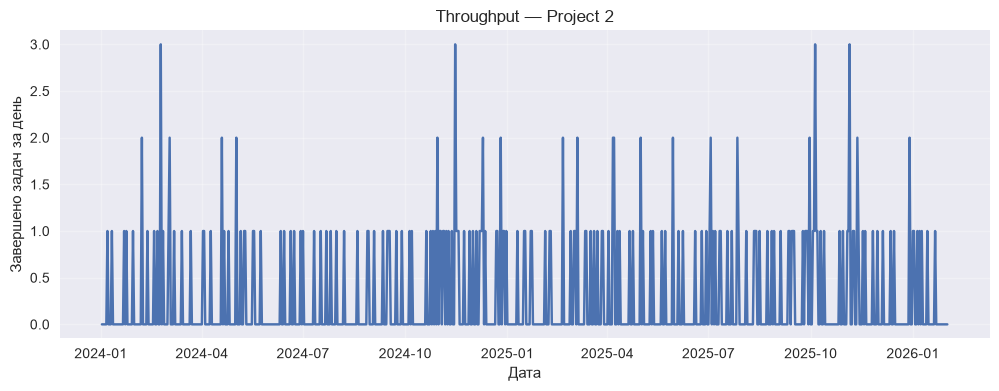

In [70]:
import matplotlib.pyplot as plt

for project_id, data in daily_throughput.groupby("project_id"):
    plt.figure(figsize=(12, 4))

    plt.plot(data["date"], data["throughput"])

    plt.title(f"Throughput — Project {project_id}")
    plt.xlabel("Дата")
    plt.ylabel("Завершено задач за день")
    plt.grid(alpha=0.3)
    plt.show()

In [71]:
# Для согласования с Cycle Time:
# WIP = задачи между первым началом и окончательным завершением

valid_tasks = df[
    df["started_at"].notna()
    & (
        df["completed_at"].isna()
        | (df["completed_at"] >= df["started_at"])
    )
].copy()

# Сколько задач началось каждый день
starts = (
    valid_tasks
    .assign(date=valid_tasks["started_at"].dt.normalize())
    .groupby(["project_id", "date"])
    .size()
    .reindex(index, fill_value=0)
)

# Сколько задач завершилось каждый день
finishes = (
    valid_tasks[valid_tasks["completed_at"].notna()]
    .assign(date=lambda x: x["completed_at"].dt.normalize())
    .groupby(["project_id", "date"])
    .size()
    .reindex(index, fill_value=0)
)

# Изменение количества задач в работе
wip_changes = starts - finishes

# WIP на конец каждого дня
daily_wip = (
    wip_changes
    .groupby(level="project_id")
    .cumsum()
    .rename("wip")
    .reset_index()
)

display(daily_wip.head())

,project_id,date,wip
0,1,2024-01-02,0
1,1,2024-01-03,0
2,1,2024-01-04,0
3,1,2024-01-05,0
4,1,2024-01-06,0


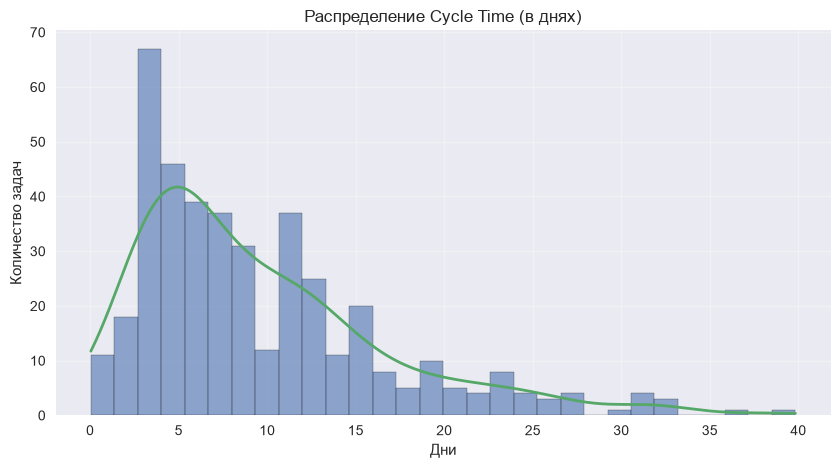

In [72]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# Берем только ненулевые и непустые значения
cycle_time = df["cycle_time_days"].dropna()
cycle_time = cycle_time[cycle_time >= 0]

plt.figure(figsize=(10, 5))

# Гистограмма
counts, bins, _ = plt.hist(
    cycle_time,
    bins=30,
    density=False,
    alpha=0.6,
    edgecolor="black"
)

# KDE-кривая
x = np.linspace(cycle_time.min(), cycle_time.max(), 300)
kde = gaussian_kde(cycle_time)

# Масштабируем кривую под гистограмму
bin_width = bins[1] - bins[0]
y = kde(x) * len(cycle_time) * bin_width

plt.plot(x, y, linewidth=2)

plt.title("Распределение Cycle Time (в днях)")
plt.xlabel("Дни")
plt.ylabel("Количество задач")
plt.grid(alpha=0.3)

plt.show()

In [73]:

# Средний Cycle Time по завершённым задачам
mean_cycle = (
    df[df["is_completed"]]
    .groupby("project_id")["cycle_time_days"]
    .mean()
    .rename("Cycle Time")
)

# Средний ежедневный Throughput (включая нулевые дни)
mean_throughput = (
    daily_throughput.groupby("project_id")["throughput"]
    .mean()
    .rename("Throughput")
)

# Средний ежедневный WIP
mean_wip = (
    daily_wip.groupby("project_id")["wip"]
    .mean()
    .rename("WIP фактический")
)

# Объединение показателей
little = pd.concat(
    [mean_cycle, mean_throughput, mean_wip],
    axis=1
)

# Расчёт WIP по закону Литтла
little["WIP расчётный"] = (
    little["Throughput"] * little["Cycle Time"]
)

# Относительное отклонение
little["Отклонение, %"] = (
    abs(
        little["WIP фактический"]
        - little["WIP расчётный"]
    )
    / little["WIP фактический"]
    * 100
)

display(little.round(2))


,Cycle Time,Throughput,WIP фактический,WIP расчётный,"Отклонение, %"
project_id,,,,,
1,9.25,0.27,9.67,2.50,74.15
2,9.94,0.27,9.02,2.72,69.78


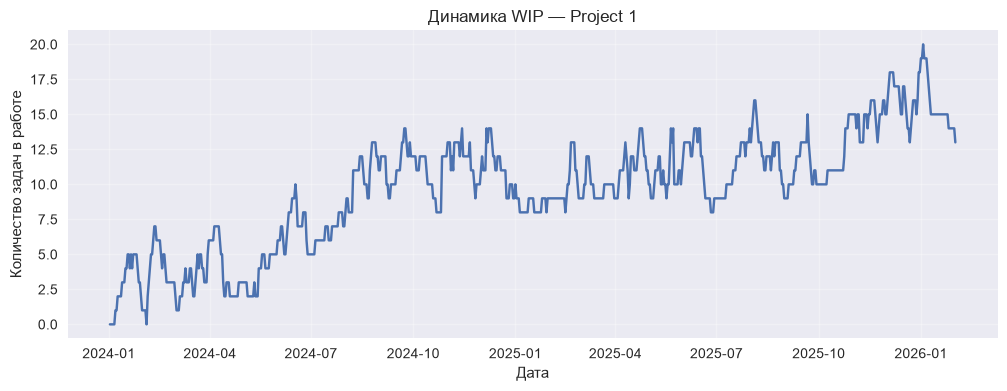

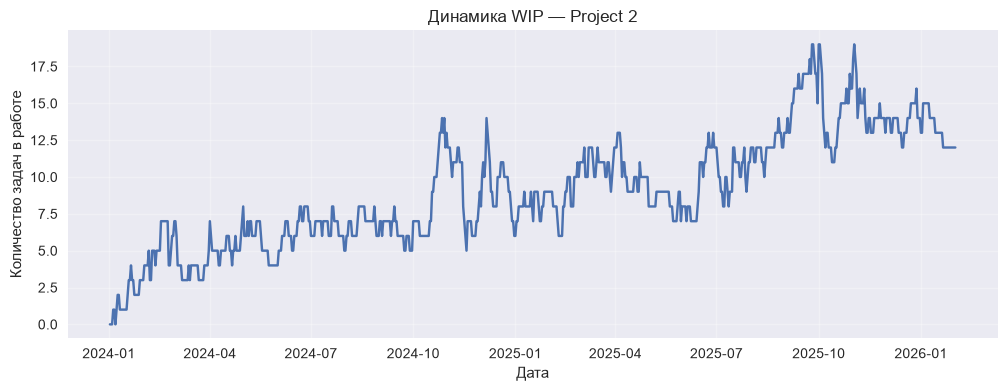

In [75]:
for project_id, data in daily_wip.groupby("project_id"):
    plt.figure(figsize=(12, 4))

    plt.plot(data["date"], data["wip"])

    plt.title(f"Динамика WIP — Project {project_id}")
    plt.xlabel("Дата")
    plt.ylabel("Количество задач в работе")
    plt.grid(alpha=0.3)

    plt.show()

In [76]:

stability_results = []

for project_id, group in df.groupby("project_id"):

    # 1. Равенство входящего и исходящего потоков
    started = group["started_at"].notna().sum()
    completed = group["is_completed"].sum()

    flow_difference = started - completed

    # 2. Постоянство среднего WIP
    wip_values = (
        daily_wip[
            daily_wip["project_id"] == project_id
        ]
        .sort_values("date")["wip"]
        .to_numpy()
    )

    middle = len(wip_values) // 2

    wip_first = wip_values[:middle].mean()
    wip_second = wip_values[middle:].mean()

    wip_change_pct = (
        (wip_second - wip_first) / wip_first * 100
        if wip_first > 0 else np.nan
    )

    # 3. Наличие начатых, но незавершённых задач
    unfinished = group[
        group["started_at"].notna()
        & ~group["is_completed"]
    ]

    # 4. Единицы измерения уже согласованы:
    # Throughput: задач/день
    # Cycle Time: дни
    # WIP: задачи

    # 5. Потенциальные заторы
    blocked = (
        group["current_status"] == "Blocked"
    ).sum()

    stability_results.append({
        "Проект": project_id,
        "Начато": started,
        "Завершено": completed,
        "Разница потоков": flow_difference,
        "WIP (1-я половина)": round(wip_first, 2),
        "WIP (2-я половина)": round(wip_second, 2),
        "Изменение WIP, %": round(wip_change_pct, 2),
        "Начато, но не завершено": len(unfinished),
        "Blocked": blocked,
        "Единицы согласованы": True
    })

stability = pd.DataFrame(stability_results)

display(stability)


,Проект,Начато,Завершено,Разница потоков,WIP (1-я половина),WIP (2-я половина),"Изменение WIP, %","Начато, но не завершено",Blocked,Единицы согласованы
0,1,219,206,13,7.29,12.05,65.20,13,4,True
1,2,221,209,12,6.34,11.70,84.67,12,8,True


In [77]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Копируем подготовленные данные
tp = daily_throughput.copy()
tp["date"] = pd.to_datetime(tp["date"])

# Убираем дни до появления первой задачи проекта
first_dates = (
    df.groupby("project_id")["created_at"]
    .min()
    .dt.normalize()
)

tp = tp[
    tp["date"] >= tp["project_id"].map(first_dates)
].copy()

tp = tp.sort_values(["project_id", "date"])

# Статистические характеристики
throughput_stats = (
    tp.groupby("project_id")["throughput"]
    .agg(
        days="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
)

# Процент дней без завершённых задач
throughput_stats["zero_days_pct"] = (
    tp.groupby("project_id")["throughput"]
    .apply(lambda x: (x == 0).mean() * 100)
)

display(throughput_stats.round(2))


,days,mean,median,std,min,max,zero_days_pct
project_id,,,,,,,
1,762,0.27,0.0,0.52,0,4,75.98
2,761,0.27,0.0,0.53,0,3,75.95


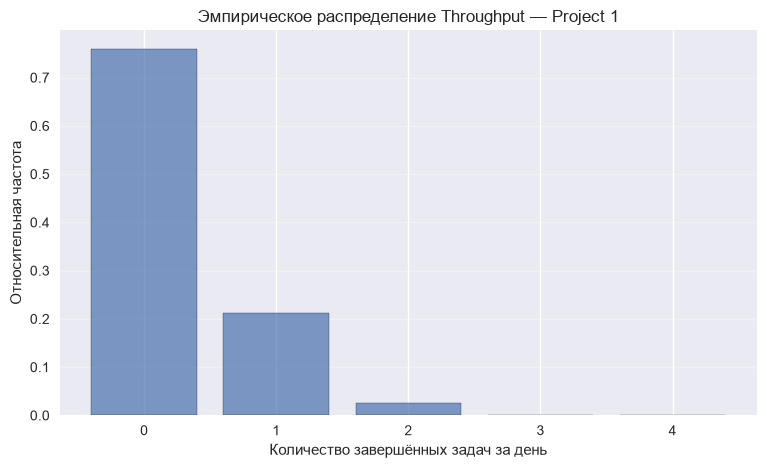

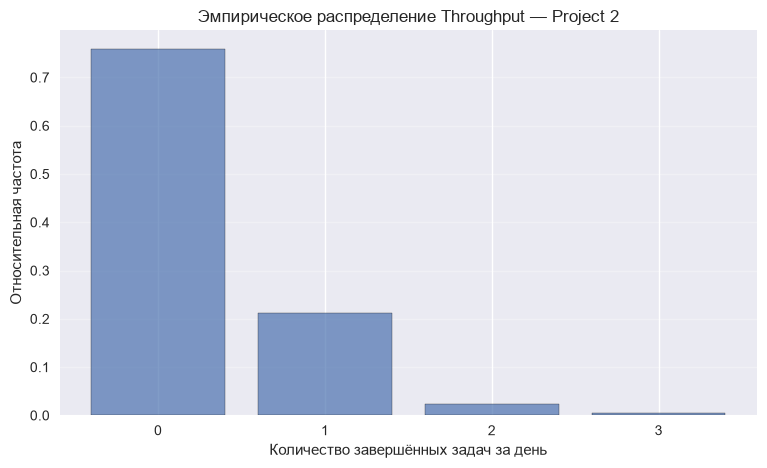

In [78]:

for project_id, group in tp.groupby("project_id"):
    counts = (
        group["throughput"]
        .value_counts(normalize=True)
        .sort_index()
    )

    x = np.arange(group["throughput"].max() + 1)
    probabilities = counts.reindex(x, fill_value=0)

    plt.figure(figsize=(9, 5))

    plt.bar(
        x,
        probabilities,
        edgecolor="black",
        alpha=0.7
    )

    plt.title(
        f"Эмпирическое распределение Throughput — "
        f"Project {project_id}"
    )
    plt.xlabel("Количество завершённых задач за день")
    plt.ylabel("Относительная частота")
    plt.xticks(x)
    plt.grid(axis="y", alpha=0.3)

    plt.show()


In [79]:

tp = tp.copy()

tp["day_number"] = tp.groupby("project_id").cumcount()

tp["total_days"] = (
    tp.groupby("project_id")["date"]
    .transform("size")
)

tp["period"] = np.where(
    tp["day_number"] < tp["total_days"] // 2,
    "Первая половина",
    "Вторая половина"
)

period_stats = (
    tp.groupby(["project_id", "period"])
    .agg(
        mean_throughput=("throughput", "mean"),
        std_throughput=("throughput", "std"),
        zero_days_pct=(
            "throughput",
            lambda x: (x == 0).mean() * 100
        )
    )
    .round(3)
)

display(period_stats)


mean_throughput  std_throughput  zero_days_pct
project_id period                                                         
1          Вторая половина            0.268           0.530         76.640
           Первая половина            0.273           0.502         75.328
2          Вторая половина            0.294           0.545         74.541
           Первая половина            0.255           0.509         77.368

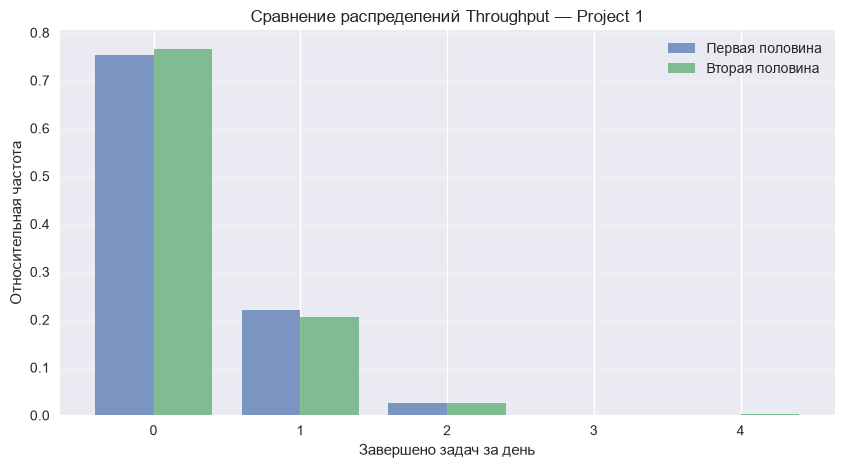

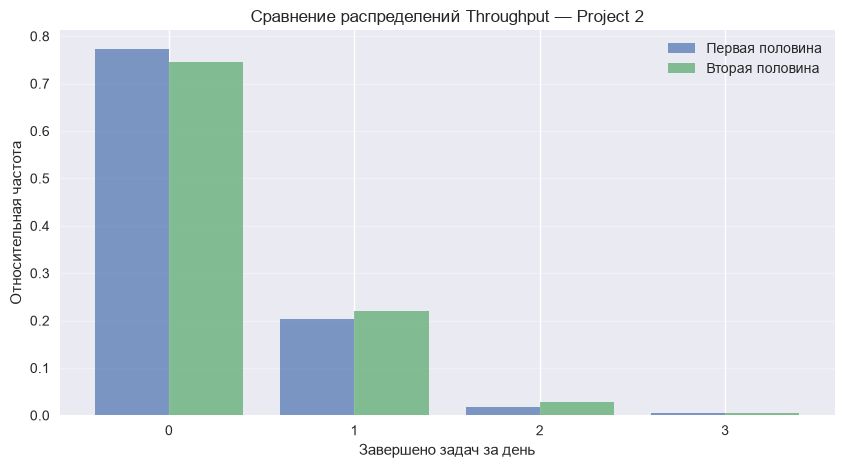

In [80]:

for project_id, group in tp.groupby("project_id"):

    first = group[
        group["period"] == "Первая половина"
    ]["throughput"]

    second = group[
        group["period"] == "Вторая половина"
    ]["throughput"]

    x = np.arange(group["throughput"].max() + 1)

    p_first = (
        first.value_counts(normalize=True)
        .reindex(x, fill_value=0)
    )

    p_second = (
        second.value_counts(normalize=True)
        .reindex(x, fill_value=0)
    )

    plt.figure(figsize=(10, 5))

    width = 0.4

    plt.bar(
        x - width / 2,
        p_first,
        width=width,
        label="Первая половина",
        alpha=0.7
    )

    plt.bar(
        x + width / 2,
        p_second,
        width=width,
        label="Вторая половина",
        alpha=0.7
    )

    plt.title(
        f"Сравнение распределений Throughput — "
        f"Project {project_id}"
    )
    plt.xlabel("Завершено задач за день")
    plt.ylabel("Относительная частота")
    plt.xticks(x)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)

    plt.show()


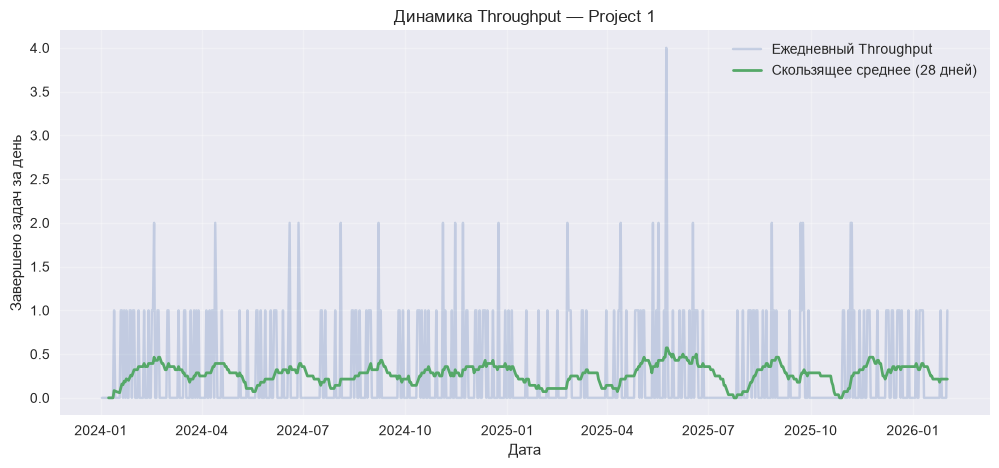

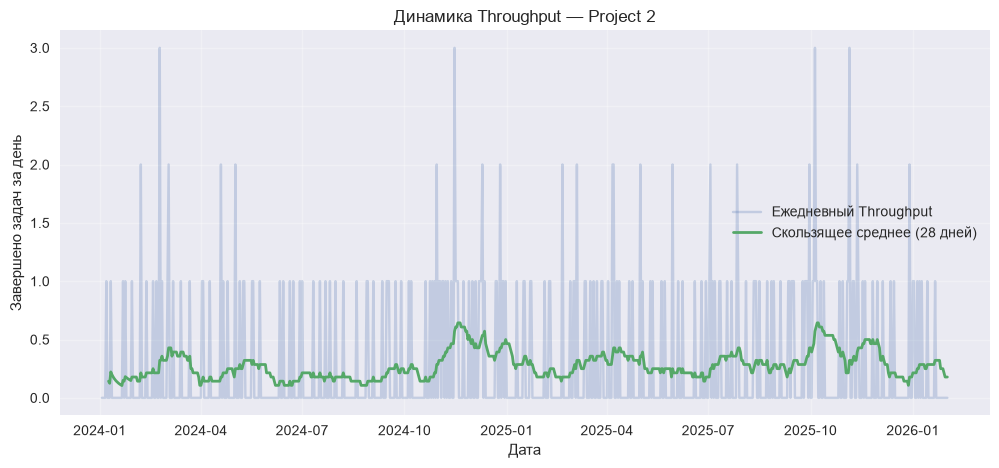

In [81]:

tp["throughput_ma28"] = (
    tp.groupby("project_id")["throughput"]
    .transform(
        lambda x: x.rolling(
            window=28,
            min_periods=7
        ).mean()
    )
)

for project_id, group in tp.groupby("project_id"):

    plt.figure(figsize=(12, 5))

    plt.plot(
        group["date"],
        group["throughput"],
        alpha=0.25,
        label="Ежедневный Throughput"
    )

    plt.plot(
        group["date"],
        group["throughput_ma28"],
        linewidth=2,
        label="Скользящее среднее (28 дней)"
    )

    plt.title(
        f"Динамика Throughput — Project {project_id}"
    )
    plt.xlabel("Дата")
    plt.ylabel("Завершено задач за день")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.show()
